# Classifying company announcements from Form 8-K extracts

**Peiqiao Xin | MA3831 Assessment 3**

## Research question

Can a model identify the type of company event in a Form 8-K extract after its official Item number and heading have been removed?

I use three classes from the US Securities and Exchange Commission (SEC):

| Item | Class used in this project |
|---|---|
| 1.01 | Material agreements |
| 2.02 | Financial results |
| 5.02 | Management or pay matters |

The Item heading provides the reference label. The model receives the extracted body text, with that heading removed. The source links are kept so that each label and passage can be checked against the filing.

Earlier research used 8-K reports to forecast later company events (Zhai & Zhang, 2019). This project focuses on sorting the event described in the current extract. I compare a majority-class baseline, TF-IDF with logistic regression, and a fine-tuned DistilBERT model.

The saved collection contains 278 extracts from 33 companies, covering filings dated 2023–2025. The sections below explain how those texts were collected, checked and used.

## Code 0. Check the software packages

This cell checks whether the required packages are installed. It installs missing packages or versions outside the stated ranges.

The collection uses Requests, BeautifulSoup and lxml. Training also needs scikit-learn, PyTorch and Transformers. The training-package option is enabled in this saved notebook.

The thread settings limit how many native computing threads are used. These settings were added after a local kernel crash. The completed training run used a CPU.

In [ ]:
# Set this to True before training. Leave it False for preview or collection.
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

INSTALL_TRAINING_PACKAGES = True

import importlib.metadata as _md
import subprocess as _subprocess
import sys as _sys
from packaging.requirements import Requirement as _Requirement
from pathlib import Path as _Path

_base = ["requests>=2.31,<3", "beautifulsoup4>=4.12,<5", "lxml>=5,<7",
         "pandas>=2,<4", "numpy>=1.26,<3", "matplotlib>=3.8,<4"]
_train = ["scikit-learn>=1.4,<2", "joblib>=1.3,<2", "torch>=2.6,<3",
          "transformers==4.55.4", "safetensors>=0.4,<1"]
_before = []
for _spec in _base + (_train if INSTALL_TRAINING_PACKAGES else []):
    _req = _Requirement(_spec)
    try:
        _version = _md.version(_req.name)
    except _md.PackageNotFoundError:
        _version = None
    if _version is None or not _req.specifier.contains(_version):
        _before.append(_spec)
if _before:
    print("Installing:", ", ".join(_before))
    _subprocess.check_call([_sys.executable, "-m", "pip", "install", "--quiet", *_before])
else:
    print("Required packages for this stage are present.")

## Code 1. Set the study options and folders

This cell sets the classes, study years, sampling limits and working folder.

| Mode | Purpose |
|---|---|
| `preview` | Test extraction on six saved A2 examples |
| `collect` | Collect the A3 corpus from SEC resources |
| `train` | Load the collected corpus and run the model experiments |

The saved notebook uses `train` mode. It reads the A3 data from `study/corpus.csv` in the working folder.

The planned sample is 300 extracts: 100 per class. Each class has a target of 33 extracts from 2023, 33 from 2024 and 34 from 2025. No company can contribute more than 15 accepted extracts.

The six industry groups are chosen sampling groups. They do not represent the proportions of all US listed companies. The first five companies in each group form the initial list, with one reserve company per group.

Seed 42 is used for the random choices. The printed folder path shows where this run reads and saves its files.

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from getpass import getpass
from hashlib import sha256
from urllib.parse import urljoin, urlsplit
from urllib.robotparser import RobotFileParser
import csv
import html
import importlib.metadata as md
import json
import os
import random
import re
import sys
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display

# Change only these settings for a normal run.
MODE = "train"                    # "preview", "collect", or "train"
USE_GOOGLE_DRIVE = False            # Set True in Colab to keep files across sessions.
LOCAL_WORK_DIR = "MA3831_A3_run"    # Used in local Jupyter.
SEED = 42
ITEMS = ["1.01", "2.02", "5.02"]
LABELS = ["Material agreements", "Financial results", "Management or pay"]
YEARS = [2023, 2024, 2025]
YEAR_GOALS = {2023: 33, 2024: 33, 2025: 34}
COMPANY_CAP = 15
MAX_ATTEMPTS = 600
MIN_WORDS = 35
MAX_MODEL_TOKENS = 512
MODEL_NAME = "distilbert/distilbert-base-uncased"
AGENT_NAME = "MA3831CourseResearch"
REQUEST_GAP_SECONDS = 2.0

# Manual sampling groups; compare with the SEC SIC description in company_roster.csv.
GROUPS = {
    "Manufacturing": ["AAPL", "BA", "CAT", "F", "GM", "GE"],
    "Transport and utilities": ["UPS", "FDX", "UNP", "DAL", "NEE", "SO"],
    "Wholesale": ["MCK", "COR", "CAH", "FAST", "GWW", "SYY"],
    "Retail": ["WMT", "COST", "TGT", "HD", "LOW", "BBY"],
    "Finance and property": ["JPM", "BAC", "GS", "PLD", "SPG", "WFC"],
    "Services": ["MSFT", "ACN", "IBM", "ADBE", "NFLX", "ORCL"],
}
PILOT_TICKERS = {"AAPL", "BA"}

assert MODE in {"preview", "collect", "train"}, "Set MODE to preview, collect, or train."
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/MA3831_A3_run")
else:
    WORK = Path(LOCAL_WORK_DIR).expanduser().resolve()
CACHE = WORK / "sec_cache"
OUT = WORK / ("preview" if MODE == "preview" else "study")
for folder in (CACHE, OUT):
    folder.mkdir(parents=True, exist_ok=True)

def utc():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def write_json(path, obj):
    path = Path(path)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    temp.replace(path)

def words(text):
    return re.findall(r"\b\w+(?:[’'-]\w+)*\b", text)

print("Mode:", MODE, "| Working folder:", WORK)

Mode: train | Working folder: /Users/16x/MA3831_A3_run


## Code 2. Read SEC metadata and filing pages

The API and webpage requests have different roles:

1. The ticker index links a stock symbol to the company's CIK, which is its SEC identifier.
2. The Submissions API returns filing dates, form types, Item codes, accession numbers and document names.
3. The code uses those fields to build an EDGAR archive URL.
4. The archive page supplies the HTML from which the body text is extracted.

An accession number identifies a filing. The CIK, accession number and document name connect the API record to its webpage. These resources belong to the SEC; they are parts of one collection process.

The client identifies the project and a contact email, checks archive access against `robots.txt`, and leaves at least two seconds between live requests. It stops when access fails or the response looks like a block page.

Successful responses are cached with their original URL, retrieval time, HTTP status and SHA-256 checksum. The checksum helps detect changes or damage to a saved response. A cached response can be reused without downloading the same page again.

In [3]:
# HTTP rules are checked before any request for a filing.
class AccessStopped(RuntimeError):
    pass

class SECClient:
    def __init__(self, cache, log_path):
        self.cache = Path(cache)
        self.log_path = Path(log_path)
        self.session = requests.Session()
        self.robots = None
        self.last_start = None
        self.email = os.environ.get("SEC_CONTACT_EMAIL", "").strip()

    def log(self, **fields):
        with self.log_path.open("a", encoding="utf-8") as file:
            file.write(json.dumps(fields, ensure_ascii=False) + "\n")

    @staticmethod
    def allowed_url(url):
        p = urlsplit(url)
        if p.scheme != "https" or p.netloc not in {"www.sec.gov", "data.sec.gov"} or p.query or p.fragment:
            return False
        if p.netloc == "www.sec.gov":
            return p.path in {"/robots.txt", "/files/company_tickers.json"} or bool(
                re.fullmatch(r"/Archives/edgar/data/\d+/\d{18}/[A-Za-z0-9_.()-]+\.html?", p.path, re.I)
            )
        return bool(re.fullmatch(r"/submissions/CIK\d{10}(?:-submissions-\d+)?\.json", p.path))

    def read(self, url, use_robots=True):
        if not self.allowed_url(url):
            raise ValueError("Unexpected SEC path: " + url)
        if "/Archives/" in url and use_robots:
            if self.robots is None:
                txt, _ = self.read("https://www.sec.gov/robots.txt", use_robots=False)
                self.robots = RobotFileParser()
                self.robots.parse(txt.decode("utf-8", errors="replace").splitlines())
            if not self.robots.can_fetch(AGENT_NAME, url):
                self.log(url=url, time_utc=utc(), origin="policy", outcome="robots_denied")
                raise AccessStopped("robots.txt disallows this filing path: " + url)

        key = sha256(url.encode()).hexdigest()
        body_file = self.cache / (key + ".body")
        meta_file = self.cache / (key + ".json")
        if body_file.exists() and meta_file.exists():
            raw, info = body_file.read_bytes(), json.loads(meta_file.read_text(encoding="utf-8"))
            if info["sha256"] != sha256(raw).hexdigest() or info["url"] != url:
                raise AccessStopped("Corrupt cache file: " + str(body_file))
            self.log(**info, origin="cache", outcome="ok", time_utc=utc())
            return raw, info

        if not self.email:
            from getpass import getpass as read_sec_email
            self.email = read_sec_email("SEC contact email (hidden): ").strip()
        if not re.fullmatch(r"[^\s@]+@[^\s@]+\.[^\s@]+", self.email):
            raise AccessStopped("A valid contact email is required for live SEC requests.")
        if self.last_start is not None:
            time.sleep(max(0, REQUEST_GAP_SECONDS - (time.monotonic() - self.last_start)))
        self.last_start = time.monotonic()
        try:
            response = self.session.get(
                url, headers={"User-Agent": f"{AGENT_NAME} {self.email}"},
                timeout=(12, 35), allow_redirects=False
            )
        except requests.RequestException as exc:
            self.log(url=url, origin="live", outcome=type(exc).__name__, time_utc=utc())
            raise AccessStopped(f"SEC connection stopped ({type(exc).__name__}). Saved responses can be reused.") from exc
        raw = response.content
        info = dict(url=url, retrieved_utc=utc(), status=response.status_code,
                    content_type=response.headers.get("Content-Type", ""), bytes=len(raw),
                    sha256=sha256(raw).hexdigest(), cf_ray=response.headers.get("CF-Ray", ""),
                    elapsed_seconds=round(response.elapsed.total_seconds(), 3))
        preview = raw[:100_000].lower()
        blocked = any(marker in preview for marker in (
            b"undeclared automated tool", b"request rate threshold exceeded",
            b"/cdn-cgi/challenge-platform", b"<title>just a moment", b"<title>access denied"
        ))
        type_ok = not url.endswith(".json") or "json" in info["content_type"].lower()
        ok = response.status_code == 200 and not blocked and type_ok and bool(raw)
        self.log(**info, origin="live", outcome=("ok" if ok else "stopped_or_missing"), time_utc=utc())
        if response.status_code in (404, 410) and not blocked:
            raise FileNotFoundError(url)
        if not ok:
            raise AccessStopped(f"SEC returned HTTP {response.status_code} or unexpected content at {url}. "
                                "Collection stopped; keep the cache, and do not bypass a block.")
        temp = body_file.with_suffix(".part")
        temp.write_bytes(raw)
        temp.replace(body_file)
        write_json(meta_file, info)
        return raw, info

    def get_json(self, url):
        return json.loads(self.read(url)[0])

ROOT = "https://data.sec.gov/submissions/"
def series_rows(series):
    cols = ["form", "items", "accessionNumber", "filingDate", "primaryDocument"]
    vals = [series.get(col, []) for col in cols]
    if len({len(v) for v in vals}) != 1:
        raise ValueError("SEC submission columns differ in length.")
    return (dict(zip(cols, row)) for row in zip(*vals))

def get_candidates(client, company, year_set):
    cik = int(company["cik"])
    url = f"{ROOT}CIK{cik:010d}.json"
    data = client.get_json(url)
    assert int(data["cik"]) == cik
    company.update(company_name=data["name"], sic=str(data.get("sic", "")),
                   sic_description=data.get("sicDescription", ""))
    filings = data["filings"]
    arrays = [(url, filings["recent"])]
    for part in filings.get("files", []):
        if part["filingTo"] >= f"{min(year_set)}-01-01" and part["filingFrom"] <= f"{max(year_set)}-12-31":
            part_url = ROOT + part["name"]
            arrays.append((part_url, client.get_json(part_url)))
    candidates, seen = [], set()
    counts = Counter()
    for source, fields in arrays:
        for row in series_rows(fields):
            year = int(row["filingDate"][:4])
            acc = row["accessionNumber"]
            if row["form"] != "8-K" or year not in year_set or acc in seen:
                continue
            seen.add(acc)
            matches = sorted(set(re.findall(r"\b\d\.\d{2}\b", row["items"] or "")) & set(ITEMS))
            if not matches:
                counts["outside_target_items"] += 1
                continue
            primary = row["primaryDocument"]
            if not re.fullmatch(r"\d{10}-\d{2}-\d{6}", acc) or not isinstance(primary, str) or not re.fullmatch(
                    r"[A-Za-z0-9_.()-]+\.html?", primary, flags=re.I):
                counts["unsupported_primary_document"] += 1
                continue
            filing_url = f"https://www.sec.gov/Archives/edgar/data/{cik}/{acc.replace('-', '')}/{primary}"
            candidates.append(dict(**company, accession=acc, filing_date=row["filingDate"], year=year,
                                   submission_items=row["items"], possible_items=matches,
                                   metadata_url=source, filing_url=filing_url))
    return candidates, counts

## Code 3. Extract and clean the body text

The HTML parser removes scripts, styles and identified hidden content. It also normalises text spacing and Unicode characters.

For each selected Item, the code finds the section boundaries, removes the official heading and stops at the next Item or signature section. Dates, amounts, units and words such as “not” remain because they may help describe the event.

Some financial-result sections mainly point to an attached release. When the main section lacks enough results text, the code looks for one matching release within the same filing folder. If it cannot identify a single suitable link, it excludes that attempt rather than choosing one without clear support.

For a linked release, extraction keeps the opening narrative and removes identified numerical tables and contact or legal endings. Each accepted record keeps both the original filing URL and the URL that supplied its text.

Texts must contain at least 35 words. The code also rejects extracts in which a recognised official Item title remains. These rules provide initial checks; comparison with the original page is still needed.

In [4]:
from bs4 import Comment, NavigableString, Tag, XMLParsedAsHTMLWarning
from warnings import catch_warnings, simplefilter

BREAK = {"p", "div", "li", "h1", "h2", "h3", "h4", "hr", "br", "tr", "section"}
HEADING = re.compile(r"^Item\s+(\d\.\d{2})(?:\s*[.:-])?\s*(.*)$", re.I)
TITLES = {
    "1.01": r"Entry\s+into\s+(?:a\s+)?Material\s+Definitive\s+Agreement",
    "2.02": r"Results\s+of\s+Operations\s+and\s+Financial\s+Condition",
    "5.02": r"Departure\s+of\s+Directors\s+or\s+Certain\s+Officers\s*;\s*Election\s+of\s+Directors\s*;\s*Appointment\s+of\s+Certain\s+Officers\s*;\s*Compensatory\s+Arrangements\s+of\s+Certain\s+Officers",
}
STOP = re.compile(r"^(?:SIGNATURES?\b|Pursuant to the requirements of the Securities Exchange Act|Exhibit Index\b)", re.I)
EX_STOP = re.compile(
    r"^(?:(?:Media|Investor|Press)\s+(?:Contacts?|Relations)|About\s+[^.]{1,90}$|"
    r"Forward[- ]Looking Statements|Safe Harbor|Cautionary (?:Note|Statement)|"
    r"(?:Consolidated|Condensed Consolidated) (?:Statements|Balance)|Financial Tables|Table \d+\.)", re.I)
EX_NUMBER = re.compile(r"(?<![\d.])99\.\d+(?![\d.])")
RESULT_TERMS = re.compile(
    r"\b(?:quarter|revenue|net income|net loss|earnings|sales|per share|EBITDA|financial results)\b", re.I)
RESULT_OPEN = re.compile(
    r"\b(?:announc\w*|report\w*|record\w*|releas\w*|publish\w*|post\w*)\b", re.I)
FURNISH = re.compile(
    r"^(?:The information (?:in|contained in|set forth in)|The foregoing information).*"
    r"(?:shall not be deemed|furnished and not filed)", re.I)

class SkipSample(ValueError):
    pass

def normalise(text):
    text = unicodedata.normalize("NFKC", html.unescape(text)).replace("\u00ad", "")
    return " ".join(text.split())

def document(raw):
    # Inline XBRL arrives as XHTML; use the HTML parser to recover inconsistent markup.
    with catch_warnings():
        simplefilter("ignore", XMLParsedAsHTMLWarning)
        soup = BeautifulSoup(raw, "lxml", from_encoding="utf-8")
    for node in list(soup.find_all(True)):
        if not node.name:
            continue
        style = str(node.get("style", "")).lower()
        if (node.name in {"style", "script", "noscript", "head", "ix:header", "ix:hidden", "ix:references"}
                or node.has_attr("hidden") or str(node.get("aria-hidden", "")).lower() == "true"
                or re.search(r"(?:display\s*:\s*none|visibility\s*:\s*hidden)", style)):
            node.decompose()
    return soup

def text_blocks(soup, omit_numeric_tables=False):
    lines, buf = [], []

    def flush():
        line = normalise("".join(buf))
        if line:
            lines.append(line)
        buf.clear()

    def visit(node):
        if isinstance(node, Comment):
            return
        if isinstance(node, NavigableString):
            buf.append(str(node))
            return
        if not isinstance(node, Tag):
            return
        name = node.name
        if name == "table" and omit_numeric_tables:
            s = normalise(node.get_text(" ", strip=True))
            # Keep layout tables when they contain prose; drop rows of mostly numbers.
            tokens = s.split()
            if tokens and sum(bool(re.search(r"\d", t)) for t in tokens) / len(tokens) > .35:
                flush()
                return
        if name in BREAK:
            flush()
        for child in node.children:
            visit(child)
        if name in BREAK:
            flush()
        elif name in {"td", "th"}:
            buf.append(" ")
    visit(soup.body or soup)
    flush()
    # Some filings put the number and the title in separate cells of one row.
    # Compact any blocks that split 'Item' from its numeric code.
    repaired = []
    for text in lines:
        if repaired and repaired[-1].lower().strip() == "item" and re.match(r"^\d\.\d{2}\b", text):
            repaired[-1] += " " + text
        else:
            repaired.append(text)
    return repaired

def clean_prose(parts):
    text = " ".join(p for p in parts if not FURNISH.match(p))
    text = re.sub(r"\bItems?\s*\d\.\d{2}\b", " ", text, flags=re.I)
    return normalise(text)

def item_section(soup, item):
    lines = text_blocks(soup)
    starts = [(i, m) for i, line in enumerate(lines) if (m := HEADING.match(line))]
    title_pattern = re.compile(r"^" + TITLES[item] + r"\s*[.:-]?\s*", re.I)
    findings = []
    for order, (start, match) in enumerate(starts):
        if match.group(1) != item:
            continue
        end = starts[order + 1][0] if order + 1 < len(starts) else len(lines)
        segment = []
        for line in lines[start+1:end]:
            if STOP.match(line):
                break
            segment.append(line)
        heading_tail = match.group(2)
        match_title = title_pattern.match(heading_tail)
        if match_title and title_pattern.sub("", heading_tail).strip():
            segment.insert(0, title_pattern.sub("", heading_tail))
        # Remove a repeated or separately formatted title, including a wrapped title.
        if segment:
            first = " ".join(segment[: min(len(segment), 5)])
            if title_pattern.match(first):
                segment = [title_pattern.sub("", first)] + segment[5:]
            elif re.match(r"^(?:Entry into|Results of Operations|Departure of Directors)\b", segment[0], re.I):
                if not re.search(r"\b(?:on|announced|entered|company|appointed|reported)\b",
                                 segment[0], re.I) or len(words(segment[0])) < 9:
                    segment = segment[1:]
        if segment:
            findings.append(segment)
    if not findings:
        raise SkipSample("item_heading_or_body_not_found")
    # A table-of-contents match is usually empty or shorter than the real section.
    return max(findings, key=lambda parts: len(words(" ".join(parts))))

def exhibit_target(soup, filing_url, main_text):
    refs = set(EX_NUMBER.findall(main_text))
    preferred = set()
    named = set()
    folder = filing_url.rsplit("/", 1)[0] + "/"
    for link in soup.find_all("a", href=True):
        url = urljoin(filing_url, link["href"])
        if url == filing_url or not url.startswith(folder) or not SECClient.allowed_url(url):
            continue
        name = normalise(link.get_text(" ", strip=True))
        filename = url.rsplit("/", 1)[-1]
        match = re.search(r"(?i)(?:ex|exhibit)[-_.]?99[-_.]?(\d+)", filename)
        numbers = set(EX_NUMBER.findall(name))
        if match:
            numbers.add("99." + match.group(1))
        is_results = bool(re.search(r"(?:press|earnings|results)\s+release|financial results", name, re.I))
        if numbers & refs:
            preferred.add(url)
        if is_results and (not refs or not numbers or numbers & refs):
            named.add(url)
    choices = (named & preferred) or preferred or named
    if len(choices) != 1:
        raise SkipSample("no_unique_results_exhibit")
    return choices.pop()

def exhibit_opening(soup):
    lines = text_blocks(soup, omit_numeric_tables=True)
    start = next((i for i, line in enumerate(lines) if len(words(line)) >= 12
                  and RESULT_OPEN.search(line) and RESULT_TERMS.search(line)), None)
    if start is None:
        raise SkipSample("no_results_opening_in_exhibit")
    kept = []
    for line in lines[start:]:
        if kept and EX_STOP.match(line):
            break
        if len(words(line)) >= 5:
            kept.append(line)
    return clean_prose(kept)

def extract_sample(client, job, item):
    raw, filing_info = client.read(job["filing_url"])
    soup = document(raw)
    parts = item_section(soup, item)
    main_text = " ".join(parts)
    body = clean_prose(parts)
    source = filing_info
    source_kind = "main item section"
    if item == "2.02":
        shows_metrics = bool(re.search(r"\d\s*(?:%|million|billion|per share)\b|\$\s*\d", body, re.I))
        if len(words(body)) < MIN_WORDS or not (shows_metrics and RESULT_TERMS.search(body)):
            url = exhibit_target(soup, job["filing_url"], main_text)
            raw, source = client.read(url)
            body = exhibit_opening(document(raw))
            source_kind = "linked results exhibit"
    if len(words(body)) < MIN_WORDS:
        raise SkipSample("below_word_minimum")
    if any(re.search(pat, body, re.I) for pat in TITLES.values()):
        raise SkipSample("official_title_remained_in_text")
    return {**{k: v for k, v in job.items() if k != "possible_items"}, "item": item,
            "label": ITEMS.index(item), "source_kind": source_kind, "text_source_url": source["url"],
            "retrieved_utc": source["retrieved_utc"], "response_sha256": source["sha256"],
            "word_count": len(words(body)), "text": body}

## Code 4. Store the original preview responses

This cell contains compressed SEC responses saved for the A2 pilot. Code 5 can restore them to test the parser on six documented examples.

The bundle holds source responses, not generated sample text. It allows the preview to run without making new filing requests.

These six examples are separate from the collected A3 corpus. They are not a replacement for the data used in training and evaluation.

In [5]:
# Original SEC responses from the A2 pilot. Do not edit.
PILOT_BUNDLE = (
    "..."
)

## Code 5. Build or load the corpus

In collection mode, the code works through the class and year targets. It gives priority to companies with fewer accepted extracts and uses the reserve list when needed.

Each filing can supply at most one accepted extract. Exact matches and near duplicates are checked against the texts already accepted. The near-duplicate check compares groups of five consecutive words, using a similarity threshold of 0.85.

The collection records why each attempted extract was kept or rejected. Successful downloads remain in the cache if access stops, and partial records are saved separately.

In training mode, this cell loads the completed collection. It checks that the collection was made in `collect` mode and that the corpus checksum matches the saved summary.

The completed run saved **278 extracts from 33 companies after 387 extraction attempts**. The planned total of 300 was not reached. Code 6 shows where the shortfall occurred.

In [6]:
def import_preview_snapshot():
    """Restore only the six documented A2 pilot filings and their sources."""
    import base64
    import gzip

    bundle = json.loads(gzip.decompress(base64.b64decode(PILOT_BUNDLE)))
    pilot_cache = WORK / "pilot_snapshot"
    pilot_cache.mkdir(exist_ok=True)
    for entry in bundle["responses"]:
        raw = base64.b64decode(entry["data"])
        info = entry["info"]
        if sha256(raw).hexdigest() != info["sha256"]:
            raise ValueError("Pilot source checksum differs.")
        key = sha256(info["url"].encode()).hexdigest()
        (pilot_cache / (key + ".body")).write_bytes(raw)
        write_json(pilot_cache / (key + ".json"), info)
    return pilot_cache, bundle["jobs"]

class CachedPreviewClient(SECClient):
    def read(self, url, use_robots=True):
        key = sha256(url.encode()).hexdigest()
        if not (self.cache / (key + ".body")).exists():
            raise FileNotFoundError("Not part of the offline pilot: " + url)
        return super().read(url, use_robots=use_robots)

def choose_companies(client, stage):
    tickers = client.get_json("https://www.sec.gov/files/company_tickers.json")
    ticker_to_cik = {r["ticker"]: int(r["cik_str"]) for r in tickers.values()}
    roster = []
    for group, names in GROUPS.items():
        for ticker in (names[:5] if stage == "initial" else names[5:]):
            if ticker not in ticker_to_cik:
                raise ValueError("Ticker not found in SEC's current index: " + ticker)
            roster.append(dict(ticker=ticker, cik=ticker_to_cik[ticker], sampling_group=group,
                               roster_stage=stage))
    return roster

def shingle_set(text):
    terms = [w.casefold() for w in words(text)]
    return set(zip(*(terms[i:] for i in range(5))))

def duplicate_of(row, accepted):
    terms = shingle_set(row["text"])
    for other, compare in accepted:
        if other["text"].casefold() == row["text"].casefold() or (
                terms and compare and
                min(len(terms), len(compare)) / max(len(terms), len(compare)) >= .85 and
                len(terms & compare) / len(terms | compare) >= .85):
            return other
    return None

def sample_from(client, roster, records, decisions):
    candidates, screened = [], Counter()
    for company in roster:
        rows, counts = get_candidates(client, company, set(YEARS))
        candidates.extend(rows)
        screened.update(counts)
    rng = random.Random(SEED + (1 if roster[0]["roster_stage"] == "reserve" else 0))
    rng.shuffle(candidates)
    priority = {r["accession"]: i for i, r in enumerate(candidates)}
    baskets = defaultdict(list)
    existing = {r["accession"] for r in records}
    for row in candidates:
        if row["accession"] not in existing:
            for item in row["possible_items"]:
                baskets[(item, row["year"])].append(row)
    selected = Counter((r["item"], r["year"]) for r in records)
    by_company = Counter(r["cik"] for r in records)
    tried = {(r["accession"], r["item"]) for r in decisions}
    accepted = [(r, shingle_set(r["text"])) for r in records]
    active = [(i, y) for y in YEARS for i in ITEMS]
    while active and len(decisions) < MAX_ATTEMPTS:
        next_active = []
        for item, year in active:
            if selected[item, year] >= YEAR_GOALS[year] or len(decisions) >= MAX_ATTEMPTS:
                continue
            options = [r for r in baskets[item, year] if r["accession"] not in existing
                       and (r["accession"], item) not in tried and by_company[r["cik"]] < COMPANY_CAP]
            if not options:
                continue
            job = min(options, key=lambda r: (by_company[r["cik"]], priority[r["accession"]]))
            acc = job["accession"]
            tried.add((acc, item))
            detail = ""
            try:
                row = extract_sample(client, job, item)
                dup = duplicate_of(row, accepted)
                if dup:
                    detail = dup["accession"]
                    raise SkipSample("near_duplicate" if dup["item"] == item else "duplicate_conflicting_label")
            except FileNotFoundError:
                status = "source_not_found"
            except SkipSample as exc:
                status = str(exc)
            else:
                status = "kept"
                records.append(row)
                accepted.append((row, shingle_set(row["text"])))
                existing.add(acc)
                selected[item, year] += 1
                by_company[row["cik"]] += 1
                if len(records) % 15 == 0:
                    print(f"Kept {len(records)} samples after {len(decisions)+1} extraction attempts.", flush=True)
            decisions.append(dict(accession=acc, item=item, year=year, ticker=job["ticker"],
                                  filing_url=job["filing_url"], outcome=status, detail=detail))
            next_active.append((item, year))
        active = next_active
    return len(candidates), dict(screened)

def build_corpus():
    records, decisions, roster_notes, screening = [], [], [], {}
    started = utc()
    if MODE == "preview":
        snapshot, jobs = import_preview_snapshot()
        client = CachedPreviewClient(snapshot, OUT / "http_log.jsonl")
        for target in jobs:
            company = {k: target[k] for k in ("cik", "ticker", "sampling_group", "roster_stage")}
            candidates, _ = get_candidates(client, company, {2025})
            job = next(r for r in candidates if r["accession"] == target["accession"])
            row = extract_sample(client, job, target["item"])
            records.append(row)
            decisions.append(dict(accession=row["accession"], item=row["item"], year=row["year"],
                                  ticker=row["ticker"], filing_url=row["filing_url"], outcome="kept", detail=""))
            if company["ticker"] not in [r["ticker"] for r in roster_notes]:
                roster_notes.append(company)
    else:
        client = SECClient(CACHE, OUT / "http_log.jsonl")
        try:
            for stage in ("initial", "reserve"):
                if stage == "reserve" and (len(records) == sum(YEAR_GOALS.values()) * len(ITEMS)
                        or len(decisions) >= MAX_ATTEMPTS):
                    break
                roster = choose_companies(client, stage)
                roster_notes.extend(roster)
                screening[stage] = sample_from(client, roster, records, decisions)
        except AccessStopped as exc:
            pd.DataFrame(records).to_csv(OUT / "partial_corpus.csv", index=False)
            pd.DataFrame(decisions).to_csv(OUT / "partial_decisions.csv", index=False)
            print(f"Saved {len(records)} partial records. Restart from Code 1 in collect mode to reuse successful downloads.")
            raise
    if not records:
        raise ValueError("No records were kept. Check the access and extraction output.")
    frame = pd.DataFrame(records)
    assert not frame["accession"].duplicated().any()
    assert frame["label"].between(0, len(ITEMS)-1).all()
    if MODE != "preview":
        assert frame.groupby("cik").size().max() <= COMPANY_CAP
    corpus_path = OUT / "corpus.csv"
    frame.to_csv(corpus_path, index=False)
    (OUT / "partial_corpus.csv").unlink(missing_ok=True)
    (OUT / "partial_decisions.csv").unlink(missing_ok=True)
    pd.DataFrame(decisions).to_csv(OUT / "sampling_decisions.csv", index=False)
    pd.DataFrame(roster_notes).to_csv(OUT / "company_roster.csv", index=False)
    write_json(OUT / "collection_summary.json", dict(mode=MODE, start_utc=started, end_utc=utc(),
               seed=SEED, samples=len(records), companies=int(frame["cik"].nunique()), attempts=len(decisions),
               a2_pilot_snapshot=(MODE == "preview"),
               screening=screening, target_per_item_year=YEAR_GOALS, company_cap=COMPANY_CAP,
               candidate_attempt_cap=MAX_ATTEMPTS, minimum_words=MIN_WORDS,
               corpus_sha256=sha256(corpus_path.read_bytes()).hexdigest()))
    print(f"Saved {len(records)} records from {frame['cik'].nunique()} companies:", corpus_path)
    return frame

if MODE in {"preview", "collect"}:
    corpus = build_corpus()
else:
    p = OUT / "corpus.csv"
    summary = json.loads((OUT / "collection_summary.json").read_text(encoding="utf-8")) if p.exists() else {}
    if summary.get("mode") != "collect":
        raise ValueError("Run collect first. Training will not use the A2 pilot or a partial collection.")
    if sha256(p.read_bytes()).hexdigest() != summary["corpus_sha256"]:
        raise ValueError("corpus.csv changed after collection. Restore the collected file before training.")
    corpus = pd.read_csv(p, dtype={"item": str}, keep_default_na=False)
    print(f"Loaded {len(corpus)} samples from {p}")

Loaded 278 samples from /Users/16x/MA3831_A3_run/study/corpus.csv


## Code 6. Review the collection and its limits

The tables show the retained counts by class and year, source types, text lengths and extraction outcomes. The figure summarises class counts, industry groups and text lengths.

The saved collection contains:

| Item | Retained extracts | Planned extracts |
|---|---:|---:|
| 1.01 | 78 | 100 |
| 2.02 | 100 | 100 |
| 5.02 | 100 | 100 |
| Total | 278 | 300 |

The 22 missing samples are all in Item 1.01. That shortfall is not the same as the number of rejected attempts: available candidates, year targets and the company limit also affect selection.

For Item 2.02, 88 attempts were excluded because the code could not identify one results exhibit. This does not mean those filings had no financial results. It shows a limit of the link-selection rule.

Source style also differs by class. Of the 100 financial-result extracts, 89 come from linked releases. All agreement and management/pay extracts come from main Item sections. A model could therefore learn differences in writing style as well as event content.

The HTTP examples show recorded requests and their origins. A cached entry retains the original retrieval time; it is not evidence of a new live request. HTTP 200 shows that a response was received, but does not prove that its text was extracted correctly.

The cell also prepares a manual review sheet with eight examples per class. At the time these notes were written, two records were marked as checked and 22 remained unmarked. The sheet displays only the opening 900 characters, so the full extract and source page should be checked before confirming a record.

year,2023,2024,2025
item,,,
1.01,25,23,30
2.02,33,33,34
5.02,33,33,34


Shortfall against the planned per-item and per-year targets:


,2023,2024,2025
1.01,8,10,4
2.02,0,0,0
5.02,0,0,0


source_kind,linked results exhibit,main item section
item,,
1.01,0,78
2.02,89,11
5.02,0,100


,count,min,median,mean,max
item,,,,,
1.01,78,86,550.5,650.653846,3848
2.02,100,111,948.5,1069.680000,3690
5.02,100,35,167.5,263.730000,1712


,ticker,filing_date,item,source_kind,text_source_url
0,BAC,2023-04-28,5.02,main item section,https://www.sec.gov/Archives/edgar/data/70858/...
1,DAL,2024-01-12,1.01,main item section,https://www.sec.gov/Archives/edgar/data/27904/...
2,UPS,2024-05-06,5.02,main item section,https://www.sec.gov/Archives/edgar/data/109072...
3,BA,2025-04-24,1.01,main item section,https://www.sec.gov/Archives/edgar/data/12927/...
4,COR,2025-08-06,2.02,linked results exhibit,https://www.sec.gov/Archives/edgar/data/114085...
5,MSFT,2025-12-08,5.02,main item section,https://www.sec.gov/Archives/edgar/data/789019...


item,1.01,2.02,5.02
outcome,,,
below_word_minimum,10,0,1
item_heading_or_body_not_found,9,0,0
kept,78,100,100
near_duplicate,1,0,0
no_unique_results_exhibit,0,88,0


,kind,url,status,origin,retrieved_utc
0,ticker index JSON,https://www.sec.gov/files/company_tickers.json,200,live,2026-11-18T09:35:19+00:00
1,submissions JSON,https://data.sec.gov/submissions/CIK0000320193...,200,live,2026-11-18T09:35:23+00:00
88,robots.txt,https://www.sec.gov/robots.txt,200,live,2026-11-18T09:38:32+00:00
89,archive HTML,https://www.sec.gov/Archives/edgar/data/927653...,200,live,2026-11-18T09:38:34+00:00


Samples by the six planned industry groups. These are design groups, not population estimates.


item,1.01,2.02,5.02
sampling_group,,,
Manufacturing,17,11,17
Transport and utilities,6,11,22
Wholesale,31,13,13
Retail,13,24,11
Finance and property,2,23,22
Services,9,18,15


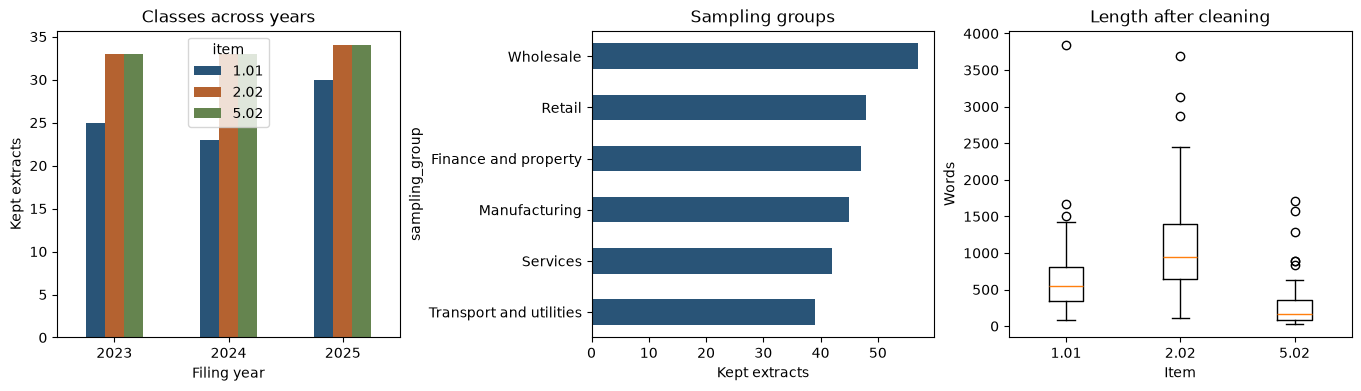

In [7]:
# Each item/year denominator is its planned count, not the number of SEC filings.
coverage = (pd.crosstab(corpus["item"], corpus["year"])
            .reindex(index=ITEMS, columns=YEARS, fill_value=0))
display(coverage)
if MODE != "preview":
    planned = pd.DataFrame([YEAR_GOALS] * len(ITEMS), index=ITEMS)
    print("Shortfall against the planned per-item and per-year targets:")
    display(planned - coverage)
display(pd.crosstab(corpus["item"], corpus["source_kind"]).reindex(ITEMS, fill_value=0))
display(corpus.groupby("item")["word_count"].agg(["count", "min", "median", "mean", "max"]))
display(corpus[["ticker", "filing_date", "item", "source_kind", "text_source_url"]].head(6))
coverage.to_csv(OUT / "class_year_counts.csv")
pd.crosstab(corpus["item"], corpus["source_kind"]).to_csv(OUT / "source_type_counts.csv")
corpus.groupby("item")["word_count"].agg(["count", "min", "median", "mean", "max"]).to_csv(
    OUT / "text_lengths.csv")
decisions = pd.read_csv(OUT / "sampling_decisions.csv", dtype={"item": str}, keep_default_na=False)
display(decisions.groupby(["outcome", "item"]).size().unstack(fill_value=0))
decisions.groupby(["outcome", "item"]).size().unstack(fill_value=0).to_csv(OUT / "sampling_outcomes.csv")
# A reproducible sheet to compare labels and text with the original webpage by hand.
audit = pd.concat([g.sample(n=min(len(g), 8), random_state=SEED) for _, g in corpus.groupby("item")])
audit = audit[["accession", "item", "filing_url", "source_kind", "text_source_url", "response_sha256", "text"]].copy()
audit["text"] = audit["text"].str.slice(0, 900)
audit = audit.rename(columns={"text": "opening_900_characters"})
audit["review_status"] = ""
audit["notes"] = ""
audit_path = OUT / "manual_audit.csv"
if audit_path.exists():
    old_review = pd.read_csv(audit_path, dtype=str, keep_default_na=False)
    audit = audit.drop(columns=["review_status", "notes"]).merge(
        old_review[["accession", "item", "text_source_url", "response_sha256", "opening_900_characters",
                    "review_status", "notes"]],
        on=["accession", "item", "text_source_url", "response_sha256", "opening_900_characters"],
        how="left", validate="one_to_one"
    ).fillna("")
audit.to_csv(audit_path, index=False)

# Show one recorded request of each type. When cache is used, the UTC timestamp
# and status are from the original request, not a new hit to the server.
http_events = pd.read_json(OUT / "http_log.jsonl", lines=True, convert_dates=False).dropna(subset=["status"])
http_events["kind"] = np.select(
    [http_events["url"].str.contains("/submissions/"), http_events["url"].str.contains("/Archives/"),
     http_events["url"].str.endswith("robots.txt")],
    ["submissions JSON", "archive HTML", "robots.txt"], default="ticker index JSON")
evidence_cols = ["kind", "url", "status", "origin", "retrieved_utc", "content_type", "cf_ray", "elapsed_seconds", "bytes", "sha256"]
evidence = http_events[http_events["outcome"].eq("ok")].groupby("kind", sort=False).head(1)[evidence_cols]
display(evidence[["kind", "url", "status", "origin", "retrieved_utc"]])
evidence.to_csv(OUT / "http_examples.csv", index=False)
request_counts = http_events.groupby(["origin", "status", "kind"]).size().rename("events").reset_index()
request_counts.to_csv(OUT / "http_event_counts.csv", index=False)
print("Samples by the six planned industry groups. These are design groups, not population estimates.")
group_counts = pd.crosstab(corpus["sampling_group"], corpus["item"]).reindex(
    index=list(GROUPS), columns=ITEMS, fill_value=0)
display(group_counts)
group_counts.to_csv(OUT / "industry_counts.csv")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), layout="constrained")
coverage.T.plot.bar(ax=axes[0], rot=0, color=["#295477", "#b46230", "#65844f"])
axes[0].set(xlabel="Filing year", ylabel="Kept extracts", title="Classes across years")
group_counts.sum(axis=1).sort_values().plot.barh(ax=axes[1], color="#295477")
axes[1].set(xlabel="Kept extracts", title="Sampling groups")
axes[2].boxplot([corpus.loc[corpus["item"] == i, "word_count"].to_numpy() for i in ITEMS])
axes[2].set(xticks=[1, 2, 3], xticklabels=ITEMS, xlabel="Item", ylabel="Words",
            title="Length after cleaning")
fig.savefig(OUT / "corpus_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## Code 7. Split the data by company

A company's extracts stay together in one set. This avoids training on some filings from a company and then testing on other filings from that same company.

The split aims for approximately 60% training, 20% validation and 20% testing. It uses class counts and set sizes to choose a suitable split. Model scores are not used to choose it. The two A2 pilot companies, AAPL and BA, stay in training.

| Set | Extracts | Companies |
|---|---:|---:|
| Training | 167 | 19 |
| Validation | 56 | 7 |
| Test | 55 | 7 |

All three classes appear in each set, and company overlap is zero.

Training fits the models. Validation selects their settings. The test set measures the selected models on other companies within the sampled years. It does not measure performance on a later time period.

In [8]:
from sklearn.model_selection import GroupShuffleSplit

def grouped_split(frame):
    labels = frame["label"].to_numpy()
    companies = frame["cik"].to_numpy()
    total = np.bincount(labels, minlength=len(ITEMS))
    if (total < 10).any() or len(set(companies)) < 8:
        raise ValueError("Too little company/class support to train and evaluate. Inspect the collection first.")
    pilot_ids = set(frame.loc[frame["ticker"].isin(PILOT_TICKERS), "cik"])
    initials = np.arange(len(frame))
    best = None
    for train, hold in GroupShuffleSplit(n_splits=360, train_size=.60, random_state=SEED).split(initials, groups=companies):
        if not pilot_ids.issubset(set(companies[train])):
            continue
        for val_i, test_i in GroupShuffleSplit(n_splits=12, test_size=.50, random_state=SEED).split(hold, groups=companies[hold]):
            splits = (train, hold[val_i], hold[test_i])
            observed = np.array([np.bincount(labels[idx], minlength=len(ITEMS)) for idx in splits])
            if (observed < np.array([[5], [3], [3]])).any():
                continue
            proportions = np.array([.6, .2, .2])
            loss = (np.abs(observed / total - proportions[:, None]).mean()
                    + np.abs(observed.sum(axis=1) / len(frame) - proportions).mean())
            if best is None or loss < best[0]:
                best = (loss, splits)
    if best is None:
        raise ValueError("No valid company split has at least 5/3/3 samples per class. Review the collection.")
    tags = np.empty(len(frame), dtype=object)
    for name, idx in zip(("train", "validation", "test"), best[1]):
        tags[idx] = name
    checks = [set(companies[idx]) for idx in best[1]]
    assert not (checks[0] & checks[1] or checks[0] & checks[2] or checks[1] & checks[2])
    assert len(frame) == len(set(frame["accession"]))
    return tags

if MODE == "train":
    corpus["split"] = grouped_split(corpus)
    split_counts = pd.crosstab(corpus["split"], corpus["item"]).reindex(
        index=["train", "validation", "test"], columns=ITEMS, fill_value=0)
    split_counts["Total"] = split_counts[ITEMS].sum(axis=1)
    split_counts["Companies"] = corpus.groupby("split")["cik"].nunique()
    splits_export = corpus[["accession", "cik", "ticker", "item", "year", "split"]]
    splits_export.to_csv(OUT / "split_assignments.csv", index=False)
    split_counts.to_csv(OUT / "split_counts.csv")
    display(split_counts)
else:
    print("Training cells are inactive in this mode.")

item,1.01,2.02,5.02,Total,Companies
split,,,,,
train,49,61,57,167,19
validation,14,19,23,56,7
test,15,20,20,55,7


## Code 8. Give both text models the same opening passage

DistilBERT processes tokens, which can be whole words or parts of words. A token count is therefore different from a word count.

The input limit is 512 tokens, including two special tokens. This leaves room for up to 510 content tokens. The code uses the tokenizer's character positions to keep the corresponding opening passage.

Both TF-IDF and DistilBERT receive this same passage. This makes their comparison clearer because one model does not receive more text than the other.

The output reports how many extracts were shortened in each class and split. In the test set, **38 of 55 extracts were truncated**, including all 20 financial-result extracts. The experiment therefore evaluates opening passages rather than complete filings.

In [9]:
if MODE == "train":
    import torch
    torch.set_num_threads(1)
    from transformers import AutoTokenizer

    # Both models receive the same opening context. The token cap includes BERT's special tokens.
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
    max_token_content = MAX_MODEL_TOKENS - tokenizer.num_special_tokens_to_add(pair=False)
    def shared_window(text):
        tokens = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True,
                           truncation=True, max_length=max_token_content + 1, verbose=False)
        spans = tokens["offset_mapping"]
        if len(spans) <= max_token_content:
            return text, len(spans), False
        last_end = spans[max_token_content - 1][1]
        return text[:last_end].rstrip(), max_token_content, True

    corpus[["model_text", "model_tokens", "truncated"]] = pd.DataFrame(
        [shared_window(t) for t in corpus["text"]], index=corpus.index)
    assert corpus["model_text"].str.len().min() > 0
    split_data = {name: corpus[corpus["split"].eq(name)].copy()
                  for name in ("train", "validation", "test")}
    token_counts = corpus.groupby(["split", "item"]).agg(
        samples=("item", "size"), truncated=("truncated", "sum"),
        median_tokens=("model_tokens", "median"))
    token_counts.to_csv(OUT / "token_window.csv")
    display(token_counts)

samples  truncated  median_tokens
split      item                                   
test       1.01       15         13          510.0
           2.02       20         20          510.0
           5.02       20          5          266.0
train      1.01       49         32          510.0
           2.02       61         55          510.0
           5.02       57         10          198.0
validation 1.01       14         11          510.0
           2.02       19         14          510.0
           5.02       23          6          237.0

## Code 9. Train the comparison models

The majority-class baseline always predicts the most common training class, Item 2.02. It shows what can be achieved without reading the text.

The word-based model combines TF-IDF and logistic regression. TF-IDF gives weight to terms based on their frequency in a passage and across the training texts. Logistic regression learns how those features relate to the three classes.

The vocabulary and TF-IDF weights are fitted on training text only. Terms must appear in at least two training extracts, and the feature limit is 25,000.

The validation comparison tests six settings:

- Single words, or single words together with word pairs.
- `C` values of 0.1, 1 and 10.

A smaller `C` places tighter limits on the learned weights. Settings are ranked by validation macro-F1, then accuracy. Ties favour single words and the smaller `C`.

All six settings score 1.0 on both validation measures in this run. The selected model therefore uses **single words and C = 0.1**. These results give no evidence that adding word pairs improves validation performance.

In [10]:
if MODE == "train":
    import joblib
    from sklearn.dummy import DummyClassifier
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, f1_score
    from sklearn.pipeline import make_pipeline

    def score(y, pred):
        return dict(macro_f1=f1_score(y, pred, labels=list(range(len(ITEMS))),
                                     average="macro", zero_division=0),
                    accuracy=accuracy_score(y, pred))

    train, val, test = (split_data[name] for name in ("train", "validation", "test"))
    tx, ty = train["model_text"].tolist(), train["label"].to_numpy()
    vx, vy = val["model_text"].tolist(), val["label"].to_numpy()
    sx, sy = test["model_text"].tolist(), test["label"].to_numpy()
    dummy = DummyClassifier(strategy="most_frequent").fit(tx, ty)
    settings, fitted = [], {}
    for ngrams in ((1, 1), (1, 2)):
        for c in (.1, 1., 10.):
            model = make_pipeline(
                TfidfVectorizer(ngram_range=ngrams, min_df=2, sublinear_tf=True,
                                token_pattern=r"(?u)\b\w[\w’'-]*\b", max_features=25_000),
                LogisticRegression(C=c, max_iter=1500, random_state=SEED)
            )
            model.fit(tx, ty)
            tag = (ngrams[1], c)
            fitted[tag] = model
            settings.append(dict(max_ngram=tag[0], C=c, **score(vy, model.predict(vx))))
    baseline_settings = pd.DataFrame(settings).sort_values(
        ["macro_f1", "accuracy", "max_ngram", "C"], ascending=[False, False, True, True])
    baseline_settings.to_csv(OUT / "tfidf_validation.csv", index=False)
    display(baseline_settings)
    choice = baseline_settings.iloc[0]
    tfidf_best = fitted[(int(choice["max_ngram"]), float(choice["C"]))]
    joblib.dump(tfidf_best, OUT / "tfidf_model.joblib")

,max_ngram,C,macro_f1,accuracy
0,1,0.1,1.0,1.0
1,1,1.0,1.0,1.0
2,1,10.0,1.0,1.0
3,2,0.1,1.0,1.0
4,2,1.0,1.0,1.0
5,2,10.0,1.0,1.0


## Code 10. Fine-tune DistilBERT

DistilBERT starts with language knowledge learned before this project. Its word representations depend on the surrounding text (Sanh et al., 2019). Fine-tuning adjusts all model weights for the three event classes.

The new prediction layers begin with untrained weights. This explains the loading message about newly initialised classifier weights.

The completed run uses:

| Setting | Value |
|---|---|
| Starting model | `distilbert/distilbert-base-uncased` |
| Device | CPU |
| Batch size | 1 |
| Epochs | 3 |
| Learning rate | 0.00002 |
| Weight decay | 0.01 |
| Warm-up | 10% of training steps |
| Maximum input | 512 tokens, including special tokens |

An epoch is one pass through the training set. After each epoch, the code measures performance on the validation set and keeps the best checkpoint.

Validation macro-F1 is the first selection measure, followed by accuracy. If both are tied, the earlier epoch is kept.

Epochs 2 and 3 both score 1.0 on validation macro-F1 and accuracy, so **epoch 2 is selected**. Training loss falls again in epoch 3, but that alone does not show better performance on new texts.

In [11]:
if MODE == "train":
    from torch.utils.data import DataLoader, Dataset
    from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding
    from transformers import get_linear_schedule_with_warmup

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    print("Training device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "(CPU; slower)")
    BATCH_SIZE = 1
    EPOCHS = 3
    LR = 2e-5

    class EncodedText(Dataset):
        def __init__(self, texts, labels):
            self.tokens = tokenizer(texts, truncation=True, max_length=MAX_MODEL_TOKENS)
            self.labels = labels

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, index):
            return {**{k: v[index] for k, v in self.tokens.items()},
                    "labels": int(self.labels[index])}

    collator = DataCollatorWithPadding(tokenizer, return_tensors="pt")
    def loader(x, y, shuffle=False):
        return DataLoader(EncodedText(x, y), batch_size=BATCH_SIZE, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(SEED), collate_fn=collator)

    def infer(model, batches):
        model.eval()
        pred, probs = [], []
        with torch.inference_mode():
            for batch in batches:
                input_ids = {k: v.to(device) for k, v in batch.items() if k != "labels"}
                prob = model(**input_ids).logits.softmax(dim=1).cpu().numpy()
                pred.extend(prob.argmax(axis=1))
                probs.extend(prob.max(axis=1))
        return np.asarray(pred), np.asarray(probs)

    train_loader, val_loader = loader(tx, ty, True), loader(vx, vy)
    bert = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(ITEMS), use_safetensors=True,
        id2label=dict(enumerate(ITEMS)), label2id={i: n for n, i in enumerate(ITEMS)}
    ).to(device)
    optimizer = torch.optim.AdamW(bert.parameters(), lr=LR, weight_decay=.01)
    steps = EPOCHS * len(train_loader)
    schedule = get_linear_schedule_with_warmup(optimizer, int(.10 * steps), steps)
    best_key, best_epoch, best_state, history = None, None, None, []
    for epoch in range(1, EPOCHS + 1):
        bert.train()
        losses = []
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            loss = bert(**{k: v.to(device) for k, v in batch.items()}).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
            optimizer.step()
            schedule.step()
            losses.append(float(loss.detach().cpu()))
        pred, _ = infer(bert, val_loader)
        row = dict(epoch=epoch, training_loss=float(np.mean(losses)), **score(vy, pred))
        history.append(row)
        print(row, flush=True)
        key = (row["macro_f1"], row["accuracy"], -epoch)
        if best_key is None or key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {name: param.detach().cpu().clone() for name, param in bert.state_dict().items()}
    pd.DataFrame(history).to_csv(OUT / "distilbert_validation.csv", index=False)
    display(pd.DataFrame(history))
    bert.load_state_dict(best_state)
    del best_state
    bert.save_pretrained(OUT / "distilbert_model", safe_serialization=True)
    tokenizer.save_pretrained(OUT / "distilbert_model")
    print(f"Best checkpoint: epoch {best_epoch}, selected by validation macro-F1 then accuracy.")

Training device: cpu (CPU; slower)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'epoch': 1, 'training_loss': 0.5519512008072552, 'macro_f1': 0.9810983397190295, 'accuracy': 0.9821428571428571}
{'epoch': 2, 'training_loss': 0.01060465012933546, 'macro_f1': 1.0, 'accuracy': 1.0}
{'epoch': 3, 'training_loss': 0.004769016844973325, 'macro_f1': 1.0, 'accuracy': 1.0}


,epoch,training_loss,macro_f1,accuracy
0,1,0.551951,0.981098,0.982143
1,2,0.010605,1.000000,1.000000
2,3,0.004769,1.000000,1.000000


Best checkpoint: epoch 2, selected by validation macro-F1 then accuracy.


## Code 11. Evaluate the selected models

This cell evaluates the selected models on the 55 test extracts.

Accuracy is the proportion of correct predictions. Precision measures how often a predicted class is correct. Recall measures how many records from a true class are found. F1 combines precision and recall, and macro-F1 gives each class equal weight.

The confusion matrices show true classes in rows and predicted classes in columns. Values on the diagonal are correct predictions.

| Model | Correct predictions | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| Majority class | 20 / 55 | 0.3636 | 0.1778 |
| TF-IDF + logistic regression | 54 / 55 | 0.9818 | 0.9804 |
| DistilBERT | 55 / 55 | 1.0000 | 1.0000 |

TF-IDF misclassifies one agreement extract as management/pay. The record is a Netflix merger filing, accession `0001193125-25-308651`. Its text includes agreement terms alongside board and stockholder matters. These topics share vocabulary, although that observation alone does not prove why the model made its mistake.

DistilBERT gets all 55 test labels correct. Its advantage over TF-IDF is one prediction. With seven test companies and one completed training run, this is limited evidence for a wider advantage.

The small case table is selected using DistilBERT outcomes. Since DistilBERT has no observed test errors, the displayed cases are correct examples. The full prediction file also contains the TF-IDF error.

The subgroup table needs care. All 20 test financial-result extracts come from linked releases, while the other 35 come from main sections. Source style and class cannot be separated using these results. Some groups are small, and no transport/utilities company appears in the test set.

The scores describe this saved sample. Further checks would need new companies, more varied layouts and independently reviewed labels.

,model,test_samples,macro_f1,accuracy
0,Majority class,55,0.177778,0.363636
1,TF-IDF + logistic,55,0.980376,0.981818
2,DistilBERT,55,1.000000,1.000000


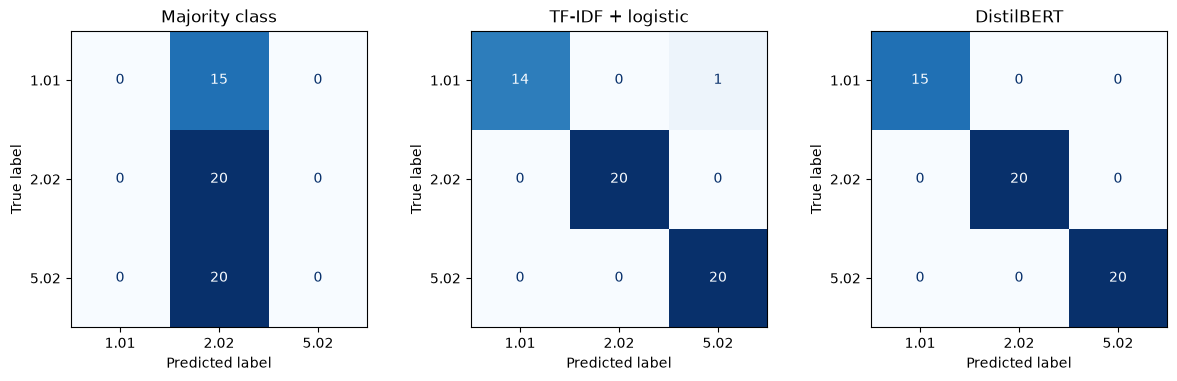

,model,item,precision,recall,f1-score,support
0,Majority class,1.01,0.000000,0.000000,0.000000,15.0
1,Majority class,2.02,0.363636,1.000000,0.533333,20.0
2,Majority class,5.02,0.000000,0.000000,0.000000,20.0
3,TF-IDF + logistic,1.01,1.000000,0.933333,0.965517,15.0
4,TF-IDF + logistic,2.02,1.000000,1.000000,1.000000,20.0
5,TF-IDF + logistic,5.02,0.952381,1.000000,0.975610,20.0
6,DistilBERT,1.01,1.000000,1.000000,1.000000,15.0
7,DistilBERT,2.02,1.000000,1.000000,1.000000,20.0
8,DistilBERT,5.02,1.000000,1.000000,1.000000,20.0


,ticker,item,tfidf_item,distilbert_item,text_source_url
123,MSFT,2.02,2.02,2.02,https://www.sec.gov/Archives/edgar/data/789019...
92,MSFT,2.02,2.02,2.02,https://www.sec.gov/Archives/edgar/data/789019...
151,MSFT,2.02,2.02,2.02,https://www.sec.gov/Archives/edgar/data/789019...
177,MSFT,2.02,2.02,2.02,https://www.sec.gov/Archives/edgar/data/789019...


,group,value,samples,companies,classes,tfidf_accuracy,distilbert_accuracy
0,source_kind,linked results exhibit,20,5,1,1.000000,1.0
1,source_kind,main item section,35,7,2,0.971429,1.0
2,item,1.01,15,4,1,0.933333,1.0
3,item,2.02,20,5,1,1.000000,1.0
4,item,5.02,20,5,1,1.000000,1.0
5,year,2023,14,6,3,1.000000,1.0
6,year,2024,17,6,3,1.000000,1.0
7,year,2025,24,7,3,0.958333,1.0
8,sampling_group,Finance and property,9,1,3,1.000000,1.0
9,sampling_group,Manufacturing,7,1,1,1.000000,1.0


Interpret subgroup scores with their sample sizes and class counts. Attachment and item may be linked.


In [12]:
if MODE == "train":
    from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

    deep_pred, deep_conf = infer(bert, loader(sx, sy))
    predictions = {"Majority class": dummy.predict(sx), "TF-IDF + logistic": tfidf_best.predict(sx),
                   "DistilBERT": deep_pred}
    scores = pd.DataFrame([{"model": model, "test_samples": len(sy), **score(sy, pred)}
                           for model, pred in predictions.items()])
    scores.to_csv(OUT / "test_metrics.csv", index=False)
    display(scores)
    details = []
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
    for ax, (name, pred) in zip(axes, predictions.items()):
        for item, item_scores in classification_report(
                sy, pred, labels=list(range(len(ITEMS))), target_names=ITEMS,
                zero_division=0, output_dict=True).items():
            if item in ITEMS:
                details.append(dict(model=name, item=item, **item_scores))
        matrix = confusion_matrix(sy, pred, labels=list(range(len(ITEMS))))
        pd.DataFrame(matrix, index=ITEMS, columns=ITEMS).to_csv(
            OUT / ("confusion_" + {"Majority class": "majority", "TF-IDF + logistic": "tfidf",
                                  "DistilBERT": "distilbert"}[name] + ".csv"))
        ConfusionMatrixDisplay(matrix, display_labels=ITEMS).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(name)
    fig.savefig(OUT / "confusion_matrices.png", dpi=160, bbox_inches="tight")
    plt.show()
    per_class = pd.DataFrame(details)
    per_class.to_csv(OUT / "test_per_class.csv", index=False)
    display(per_class)

    samples = test[["accession", "ticker", "year", "item", "sampling_group",
                    "source_kind", "text_source_url", "truncated", "word_count", "model_text"]].copy()
    samples["tfidf_item"] = [ITEMS[i] for i in predictions["TF-IDF + logistic"]]
    samples["distilbert_item"] = [ITEMS[i] for i in deep_pred]
    samples["distilbert_confidence"] = deep_conf
    samples["tfidf_correct"] = samples["tfidf_item"].eq(samples["item"])
    samples["deep_correct"] = samples["distilbert_item"].eq(samples["item"])
    samples["opening_450_characters"] = samples.pop("model_text").str.slice(0, 450)
    samples.to_csv(OUT / "test_predictions_local.csv", index=False)
    examples = pd.concat([samples[samples["deep_correct"]].nlargest(4, "distilbert_confidence"),
                          samples[~samples["deep_correct"]].nlargest(6, "distilbert_confidence")])
    examples.to_csv(OUT / "case_review_local.csv", index=False)
    display(examples[["ticker", "item", "tfidf_item", "distilbert_item", "text_source_url"]])

    grouped_rows = []
    for condition in ("source_kind", "item", "year", "sampling_group", "truncated"):
        for name, rows in samples.groupby(condition):
            grouped_rows.append(dict(group=condition, value=str(name), samples=len(rows),
                                     companies=rows["ticker"].nunique(),
                                     classes=rows["item"].nunique(),
                                     tfidf_accuracy=rows["tfidf_correct"].mean(),
                                     distilbert_accuracy=rows["deep_correct"].mean()))
    subgroup = pd.DataFrame(grouped_rows)
    subgroup.to_csv(OUT / "test_subgroups.csv", index=False)
    display(subgroup)
    print("Interpret subgroup scores with their sample sizes and class counts. Attachment and item may be linked.")

    pkgs = ["pandas", "numpy", "requests", "beautifulsoup4", "lxml", "matplotlib",
            "scikit-learn", "joblib", "torch", "transformers", "safetensors"]
    versions = {name: md.version(name) for name in pkgs}
    write_json(OUT / "training_summary.json", dict(
        completed_utc=utc(), corpus_sha256=sha256((OUT / "corpus.csv").read_bytes()).hexdigest(),
        python=sys.version.split()[0], versions=versions, device=str(device),
        gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else None, seed=SEED,
        model_source=MODEL_NAME, model_revision=getattr(bert.config, "_commit_hash", None),
        batch_size=BATCH_SIZE, max_tokens=MAX_MODEL_TOKENS, planned_epochs=EPOCHS,
        weight_decay=.01, warmup_fraction=.1, weight_clip=1., learning_rate=LR,
        best_epoch=best_epoch, tfidf_max_ngram=int(choice["max_ngram"]), tfidf_C=float(choice["C"])
    ))

## Code 12. Save the handover files

This cell writes the README, package requirements and Git ignore rules. It also saves a source manifest containing filing identifiers, URLs, checksums and split assignments, without the full extracted text.

The collection and training summaries record the corpus SHA-256 checksum. Matching values link the reported model results to the same collected dataset.

The repository should include the completed notebook, report, run instructions, source manifest, result tables and original figures. Keep the local corpus and response cache together so that the saved run can still be checked.

A fresh crawl may produce different data as SEC records and available filings change. The saved source manifest and split assignments help explain those differences. Before uploading, check that the Notebook filename in the README matches the actual file.

In [13]:
git_folder = WORK / "git_files"
git_folder.mkdir(exist_ok=True)
git_files = {
"README.md": """# MA3831 Assessment 3: Classifying company announcements

This notebook tests whether a model can assign a category to an extract from a US company's
Form 8-K after the official item heading is removed. The categories are material agreements
(1.01), financial results (2.02), and management or pay (5.02).

## Run the notebook

1. Open `A3_Peiqiao_Xin.ipynb` in Jupyter or Colab. Python 3.11 or 3.12 is recommended
   for local use. Code 0 installs the packages needed for each mode.
2. Code 1: leave `MODE = "preview"` to verify the parser on six saved SEC filings.
   Preview runs offline after the basic packages are installed; it does not train a model.
3. Set `MODE = "collect"`, run from Code 0, and enter a contact email when asked.
   The SEC Submissions API gives dates, filing identifiers and HTML filenames. The crawler
   reads the original EDGAR HTML and follows a linked results release when needed.
   Use the same work folder for all stages. Do not bypass access restrictions.
4. Review `study/manual_audit.csv` using the supplied source links. Check collection
   counts and exclusions. The targets are quotas; the output reports actual attainment.
5. Set `MODE = "train"`, run from Code 0 and keep the same working folder. A GPU is
   helpful for DistilBERT. Models share a piece of text capped at 512 tokens including
   special tokens. Companies never cross split boundaries. Validation chooses the TF-IDF
   setting and the DistilBERT checkpoint before the held-out test.
6. The results are in `study/` under the working folder, with CSV tables and PNG figures.
   Compare `training_summary.json` and `collection_summary.json` to tie results to a
   corpus checksum and runtime. New SEC downloads can differ from the original run.

## Sources and repository contents

- [SEC Submissions API](https://www.sec.gov/edgar/sec-api-documentation)
- [SEC EDGAR access guidance](https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data)
- [Form 8-K](https://www.sec.gov/files/form8-k.pdf)
- [DistilBERT model](https://huggingface.co/distilbert/distilbert-base-uncased)

The notebook contains a small, attributed preview from saved SEC responses. Keep repositories
private unless course instructions allow public sharing and you have checked reuse terms.
Share harvested text or copies of source documents only when permitted. The notebook and
this README are sufficient to run the pipeline; metrics, a URL-only source manifest, and plots
can be shared separately. Do not commit raw caches, credentials, or model weights.
""",
"requirements.txt": """requests>=2.31,<3
beautifulsoup4>=4.12,<5
lxml>=5,<7
pandas>=2,<4
numpy>=1.26,<3
matplotlib>=3.8,<4
scikit-learn>=1.4,<2
joblib>=1.3,<2
torch>=2.6,<3
transformers==4.55.4
safetensors>=0.4,<1
""",
".gitignore": """MA3831_A3_run/
sec_cache/
pilot_snapshot/
study/
preview/
.env
.env.*
*.pt
*.pth
*.joblib
*.safetensors
__pycache__/
.ipynb_checkpoints/
.DS_Store
""",
}
for name, content in git_files.items():
    (git_folder / name).write_text(content, encoding="utf-8")
if MODE == "train":
    provenance = corpus[["accession", "cik", "ticker", "filing_date", "item", "sampling_group",
                         "filing_url", "metadata_url", "text_source_url", "source_kind", "retrieved_utc",
                         "response_sha256", "word_count", "split"]]
    provenance.to_csv(OUT / "source_manifest_no_text.csv", index=False)
print("Notebook work folder:", WORK)
print("Tables and figures:", OUT)
print("Git starter files:", git_folder, "| Upload them together with this .ipynb.")

Notebook work folder: /Users/16x/MA3831_A3_run
Tables and figures: /Users/16x/MA3831_A3_run/study
Git starter files: /Users/16x/MA3831_A3_run/git_files | Upload them together with this .ipynb.


## Manual source check: read the selected record

This cell displays one record from the review sheet. It shows the reference Item, original filing URL, text-source URL and the opening 900 characters.

For the selected Delta record, the passage describes an agreement to buy Airbus aircraft. The event fits Item 1.01 because it concerns entering an agreement.

This is a source and extraction check. It is separate from measuring model accuracy. The preview helps locate the passage, but confirming the full extraction also requires reading the full saved text and checking its boundaries against the source.

In [19]:
audit = pd.read_csv(
    OUT / "manual_audit.csv",
    dtype=str,
    keep_default_na=False
)

row_number = 1

print("Reference item:", audit.loc[row_number, "item"])
print("Original filing:", audit.loc[row_number, "filing_url"])
print("Text source:", audit.loc[row_number, "text_source_url"])
print(audit.loc[row_number, "opening_900_characters"])

Reference item: 1.01
Original filing: https://www.sec.gov/Archives/edgar/data/27904/000168316824000244/delta_8k.htm
Text source: https://www.sec.gov/Archives/edgar/data/27904/000168316824000244/delta_8k.htm
On January 11, 2024, Delta Air Lines, Inc. (“Delta”) entered into a definitive agreement with Airbus S.A.S. to purchase 20 Airbus A350-1000 aircraft, with an option to purchase up to an additional 20 widebody aircraft. Deliveries of the A350-1000 aircraft will begin in 2026. In addition to improved fuel efficiency, these aircraft will add higher gauge, including more premium seating and greater cargo capabilities, to Delta’s international widebody fleet. The order for the aircraft is within Delta’s previously announced capital expenditure and capacity targets.


## Manual source check: save the review note

This cell marks the selected record as checked and saves the review note to `manual_audit.csv`.

Run it only after comparing that record with its source. The note must describe the record that was actually reviewed. The current note refers specifically to Delta's aircraft purchase agreement.

Saving a “checked” status records the reviewer's decision; it does not perform an automatic source check.

In [20]:
audit.loc[row_number, "review_status"] = "checked"
audit.loc[row_number, "notes"] = "Item 1.01: aircraft purchase agreement. Text matches the original section."
audit.to_csv(OUT / "manual_audit.csv", index=False)

## References

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. In *Proceedings of the 2019 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies, Volume 1 (Long and Short Papers)* (pp. 4171–4186). Association for Computational Linguistics. https://doi.org/10.18653/v1/N19-1423

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. In *International Conference on Learning Representations*. https://arxiv.org/abs/1711.05101

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Richardson, L. (n.d.). *Beautiful Soup documentation*. Retrieved November 19, 2026, from https://www.crummy.com/software/BeautifulSoup/bs4/doc/

Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0

Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: Smaller, faster, cheaper and lighter*. arXiv. https://doi.org/10.48550/arXiv.1910.01108

scikit-learn developers. (n.d.-a). *f1_score*. In *scikit-learn documentation*. Retrieved November 19, 2026, from https://scikit-learn.org/1.9/modules/generated/sklearn.metrics.f1_score.html

scikit-learn developers. (n.d.-b). *GroupShuffleSplit*. In *scikit-learn documentation*. Retrieved November 19, 2026, from https://scikit-learn.org/1.9/modules/generated/sklearn.model_selection.GroupShuffleSplit.html

U.S. Securities and Exchange Commission. (2024, June 6). *EDGAR application programming interfaces (APIs).* https://www.sec.gov/search-filings/edgar-application-programming-interfaces

U.S. Securities and Exchange Commission. (2025a, March 10). *Developer resources.* https://www.sec.gov/about/developer-resources

U.S. Securities and Exchange Commission. (2025b). *Form 8-K.* https://www.sec.gov/files/form8-k.pdf

Zhai, S., & Zhang, Z. (2019). Forecasting firm material events from 8-K reports. In *Proceedings of the Second Workshop on Economics and Natural Language Processing* (pp. 22–30). Association for Computational Linguistics. https://doi.org/10.18653/v1/D19-5104